# Testing Attention on Transitive Inference Tasks
The purpose of this notebook is to train various forms of attentions on both transitive inference tasks.

## Imports

In [1]:
import torch
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt

from relational_attention.tasks import TransitiveInferenceDataset, TransitiveSequenceDataset
from relational_attention.models import SelfAttentionHead, RelationalAttentionHead, AttentionClassifier
from relational_attention.training import train_model, evaluate_model

In [2]:
torch.manual_seed(42)

## Paired transitive inference task

### Build task

In [3]:
# Parameters
num_samples = 1000
num_items = 5

In [4]:
# Training task
dataset_train = TransitiveInferenceDataset(num_samples=num_samples, num_items=num_items)
loader_train = DataLoader(dataset_train, batch_size=16, shuffle=True)

In [5]:
# Testing task
dataset_test = TransitiveInferenceDataset(num_samples=num_samples, num_items=num_items, train=False)
loader_test = DataLoader(dataset_test, batch_size=16, shuffle=True)

### Initialize models

In [6]:
# Self attention head with softmax
model_self_attn = AttentionClassifier(
    embed_dim=num_items, head_dim=num_items, context_size=2, attn_cls=SelfAttentionHead
)

# Linear self attention head
model_linear_self = AttentionClassifier(
    embed_dim=num_items, head_dim=num_items, context_size=2, attn_cls=SelfAttentionHead, linear=True
)

# Relational attention head with softmax
model_relat_attn = AttentionClassifier(
    embed_dim=num_items, head_dim=num_items, context_size=2, attn_cls=RelationalAttentionHead
)

# Linear relational attention head
model_linear_relat = AttentionClassifier(
    embed_dim=num_items, head_dim=num_items, context_size=2, attn_cls=RelationalAttentionHead, linear=True
)

### Train models on paird inference

In [7]:
lr = 1e-3
loss_fn = torch.nn.BCEWithLogitsLoss()
epochs = 250

In [8]:
optimizer = torch.optim.Adam(model_self_attn.parameters(), lr=lr)
loss_self_attn = train_model(model_self_attn, loader_train, optimizer=optimizer, loss_fn=loss_fn, epochs=epochs,)

Training: 100%|██████████| 250/250 [00:08<00:00, 30.20it/s, loss=0.0000]


In [9]:
optimizer = torch.optim.Adam(model_linear_self.parameters(), lr=lr)
loss_linear_self = train_model(model_linear_self, loader_train, optimizer=optimizer, loss_fn=loss_fn, epochs=epochs,)

Training: 100%|██████████| 250/250 [00:07<00:00, 34.56it/s, loss=0.0000]


In [10]:
optimizer = torch.optim.Adam(model_relat_attn.parameters(), lr=lr)
loss_relat_attn = train_model(model_relat_attn, loader_train, optimizer=optimizer, loss_fn=loss_fn, epochs=epochs,)

Training: 100%|██████████| 250/250 [00:07<00:00, 32.99it/s, loss=0.0000]


In [11]:
optimizer = torch.optim.Adam(model_linear_relat.parameters(), lr=lr)
loss_linear_relat = train_model(model_linear_relat, loader_train, optimizer=optimizer, loss_fn=loss_fn, epochs=epochs,)

Training: 100%|██████████| 250/250 [00:07<00:00, 35.61it/s, loss=0.0000]


### Plot training dynamics

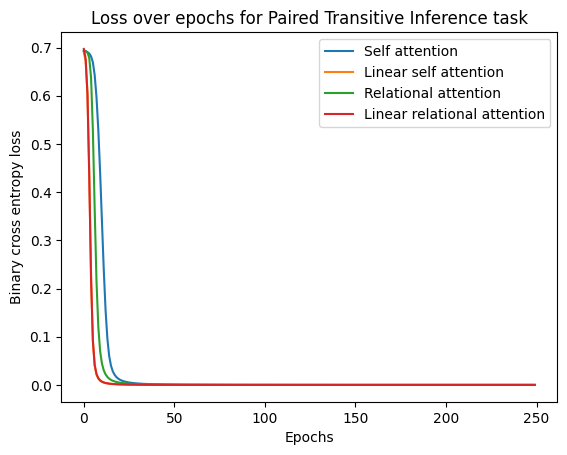

In [12]:
plt.plot(loss_self_attn, label='Self attention')
plt.plot(loss_linear_self, label='Linear self attention')
plt.plot(loss_relat_attn, label='Relational attention')
plt.plot(loss_linear_relat, label='Linear relational attention')

plt.xlabel('Epochs')
plt.ylabel('Binary cross entropy loss')
plt.title('Loss over epochs for Paired Transitive Inference task')
plt.legend()
plt.show()

### Testing models

In [13]:
acc_self = evaluate_model(model_self_attn, loader_test)
acc_linear_self = evaluate_model(model_linear_self, loader_test)
acc_relat = evaluate_model(model_relat_attn, loader_test)
acc_linear_relat = evaluate_model(model_linear_relat, loader_test)

print("Self-attention:", acc_self)
print("Linear Self-attention:", acc_linear_self)
print("Relational attention:", acc_relat)
print("Linear Relational attention:", acc_linear_relat)

Self-attention: 0.439
Linear Self-attention: 0.671
Relational attention: 1.0
Linear Relational attention: 1.0


### Save model

In [14]:
metadata = {
    "embed_dim": num_items,
    "head_dim": num_items,
    "context_size": 2,
    "pooling": "flatten",
    "num_epochs": epochs,
    "train_loss_curve": loss_linear_relat,  # if available
}

torch.save({
    "model_state": model_linear_relat.state_dict(),
    "metadata": metadata,
}, "../../data/linear_relational_attention_transitive_inference_full.pt")

## Sequence transitive inference task

### Build task

In [15]:
# Parameters
num_samples = 1000
num_items = 8
n_seq = 5

In [16]:
dataset = TransitiveSequenceDataset(num_samples=num_samples, num_items=num_items, n_seq=n_seq)
loader = DataLoader(dataset, batch_size=16, shuffle=True)

### Initialize models

In [17]:
# Self attention head with softmax
model_self_attn = AttentionClassifier(
    embed_dim=num_items, head_dim=num_items, context_size=n_seq, attn_cls=SelfAttentionHead
)

# Linear self attention head
model_linear_self = AttentionClassifier(
    embed_dim=num_items, head_dim=num_items, context_size=n_seq, attn_cls=SelfAttentionHead, linear=True
)

# Relational attention head with softmax
model_relat_attn = AttentionClassifier(
    embed_dim=num_items, head_dim=num_items, context_size=n_seq, attn_cls=RelationalAttentionHead
)

# Linear relational attention head
model_linear_relat = AttentionClassifier(
    embed_dim=num_items, head_dim=num_items, context_size=n_seq, attn_cls=RelationalAttentionHead, linear=True
)

### Train models on squence transitive inference

In [18]:
epochs = 250
optimizer = torch.optim.Adam(model_self_attn.parameters(), lr=1e-3)
loss_fn = torch.nn.BCEWithLogitsLoss()

In [19]:
optimizer = torch.optim.Adam(model_self_attn.parameters(), lr=lr)
loss_self_attn = train_model(model_self_attn, loader, optimizer=optimizer, loss_fn=loss_fn, epochs=epochs,)

Training: 100%|██████████| 250/250 [00:08<00:00, 30.12it/s, loss=0.0070]


In [20]:
optimizer = torch.optim.Adam(model_linear_self.parameters(), lr=lr)
loss_linear_self = train_model(model_linear_self, loader, optimizer=optimizer, loss_fn=loss_fn, epochs=epochs,)

Training: 100%|██████████| 250/250 [00:08<00:00, 30.83it/s, loss=0.0000]


In [21]:
optimizer = torch.optim.Adam(model_relat_attn.parameters(), lr=lr)
loss_relat_attn = train_model(model_relat_attn, loader, optimizer=optimizer, loss_fn=loss_fn, epochs=epochs,)

Training: 100%|██████████| 250/250 [00:08<00:00, 29.32it/s, loss=0.0001]


In [22]:
optimizer = torch.optim.Adam(model_linear_relat.parameters(), lr=lr)
loss_linear_relat = train_model(model_linear_relat, loader, optimizer=optimizer, loss_fn=loss_fn, epochs=epochs,)

Training: 100%|██████████| 250/250 [00:07<00:00, 34.93it/s, loss=0.0000]


### Plot training dynamics

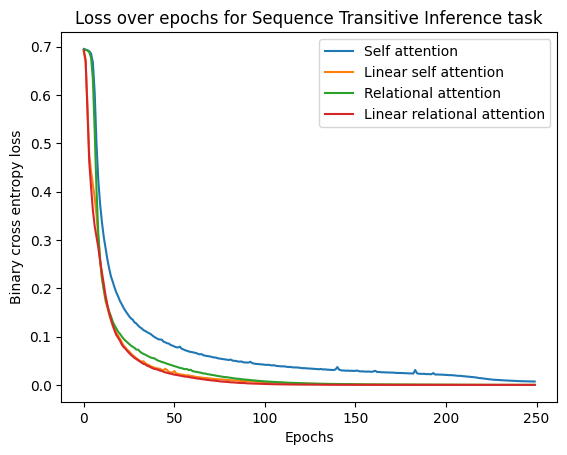

In [23]:
plt.plot(loss_self_attn, label='Self attention')
plt.plot(loss_linear_self, label='Linear self attention')
plt.plot(loss_relat_attn, label='Relational attention')
plt.plot(loss_linear_relat, label='Linear relational attention')

plt.xlabel('Epochs')
plt.ylabel('Binary cross entropy loss')
plt.title('Loss over epochs for Sequence Transitive Inference task')
plt.legend()
plt.show()